#PHASE 1


*   data preparation and exploration
*   load CIFAR-10


*   inspect dataset and class distribution

*  display 10 random labelled images
*   Normalize Images


*  Apply data augmentation





In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split

In [ ]:
BATCH_SIZE = 128
RANDOM_SEED = 42
NUM_CLASSES = 10

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", device)
print("Batch Size:", BATCH_SIZE)

Device: cpu
Batch Size: 128


In [ ]:
train_raw = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True
)

test_raw = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True
)

print("Training samples:", len(train_raw))
print("Testing samples:", len(test_raw))

100%|██████████| 170M/170M [01:25<00:00, 1.99MB/s]


Training samples: 50000
Testing samples: 10000


In [ ]:
#inspect dataset
classes = train_raw.classes

print("Classes:", classes)
print("Total Classes:", len(classes))

image, label = train_raw[0]

print("\nImage Shape:", np.array(image).shape)
print("Label:", label)
print("Class Name:", classes[label])

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Total Classes: 10

Image Shape: (32, 32, 3)
Label: 6
Class Name: frog


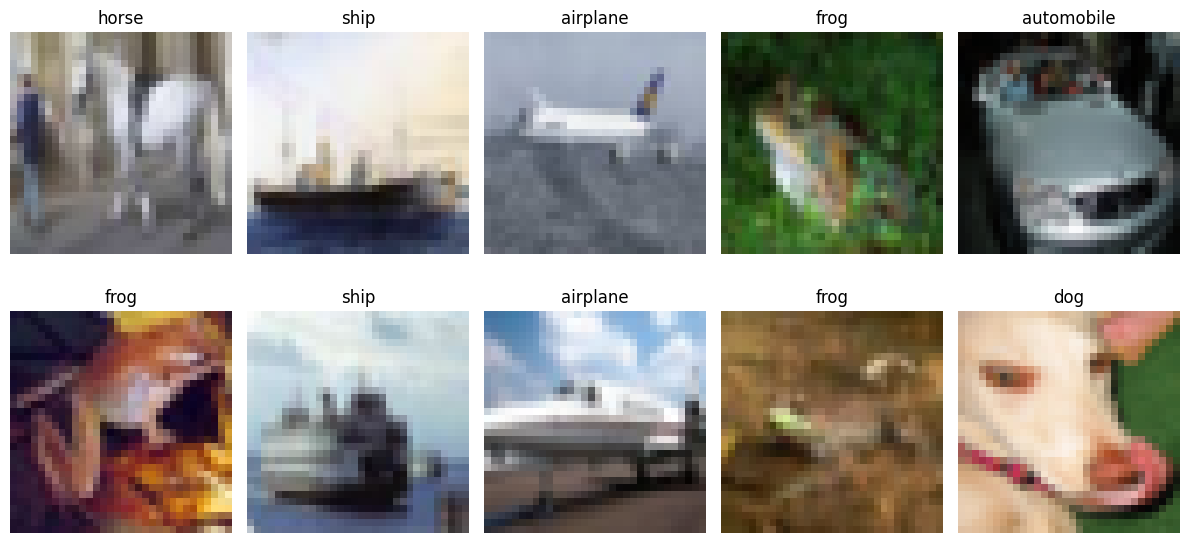

In [ ]:
#Visualise 10 random images with class labels
# Select 10 random image indices
np.random.seed(RANDOM_SEED)

random_indices = np.random.choice(
    len(train_raw),
    size=10,
    replace=False
)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for ax, idx in zip(axes.flatten(), random_indices):

    image, label = train_raw[idx]

    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#Define image transformations and normalisation

# Transformations for training data
train_transform = transforms.Compose([

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(15),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])


# Transformations for validation and testing data
test_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

In [ ]:
# Split training data into 45,000 training and 5,000 validation images
train_indices, val_indices = random_split(
    range(len(train_raw)),
    [45000, 5000],
    generator=torch.Generator().manual_seed(RANDOM_SEED)
)

# Create datasets with different transformations
train_dataset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=False,
    transform=train_transform
)

val_dataset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=False,
    transform=test_transform
)

# Apply the split indices
train_dataset = torch.utils.data.Subset(train_dataset, train_indices.indices)
val_dataset = torch.utils.data.Subset(val_dataset, val_indices.indices)

# Test dataset
test_raw.transform = test_transform
test_dataset = test_raw

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 45000
Validation: 5000
Testing: 10000


In [ ]:


BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 352
Validation batches: 40
Testing batches: 79


In [ ]:
#inspect 1 batch
images, labels = next(iter(train_loader))

print("Images Shape:", images.shape)
print("Labels Shape:", labels.shape)
print("Image Data Type:", images.dtype)
print("Label Data Type:", labels.dtype)

Images Shape: torch.Size([128, 3, 32, 32])
Labels Shape: torch.Size([128])
Image Data Type: torch.float32
Label Data Type: torch.int64


#PHASE

The phase includes:
1. Build the CNN architecture.
2. Initialise the model.
3. Configure loss function and optimiser.
4. Train the model.
5. Validate after every epoch.
6. Save the best model.
7. Plot training and validation graphs.
8. Evaluate on test data.
9. Generate a confusion matrix and classification report.

In [ ]:
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [ ]:
#define CNN architecture

class CIFAR10_CNN(nn.Module):

    def __init__(self):
        super(CIFAR10_CNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.3),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.4),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
#initialize the model

model = CIFAR10_CNN().to(device)

print(model)

CIFAR10_CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.2, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, cei

In [ ]:
#Test the model output
sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

outputs = model(sample_images)

print("Input Shape:", sample_images.shape)
print("Output Shape:", outputs.shape)

Input Shape: torch.Size([128, 3, 32, 32])
Output Shape: torch.Size([128, 10])


In [ ]:
#Define loss function and optimiser
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0005
)

#learning Rate schdeuler
EPOCHS = 30

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

In [ ]:
# Set training parameters. nd early stopping
best_val_accuracy = 0.0

patience = 5
counter = 0

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

In [ ]:
#training nd validation loop with early stopping

for epoch in range(EPOCHS):

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # Validation
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    # Store metrics
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Early Stopping and Save Best Model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        counter = 0

        torch.save(
            model.state_dict(),
            "best_cifar10_cnn.pth"
        )

        print("Best model saved!")

    else:
        counter += 1

    scheduler.step()

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.2f}% "
        f"Counter: {counter}/{patience}"
    )

    # Stop if validation accuracy does not improve
    if counter >= patience:

        print("\nEarly Stopping Triggered!")
        break

print("\nBest Validation Accuracy:", round(best_val_accuracy, 2), "%")

Best model saved!
Epoch [1/30] Train Loss: 1.6011 Train Acc: 39.69% Val Loss: 1.3797 Val Acc: 50.40% Counter: 0/5
Best model saved!
Epoch [2/30] Train Loss: 1.2672 Train Acc: 54.31% Val Loss: 1.1233 Val Acc: 60.32% Counter: 0/5
Best model saved!
Epoch [3/30] Train Loss: 1.1380 Train Acc: 59.83% Val Loss: 0.9572 Val Acc: 65.60% Counter: 0/5
Best model saved!
Epoch [4/30] Train Loss: 1.0552 Train Acc: 62.80% Val Loss: 0.8999 Val Acc: 68.02% Counter: 0/5
Best model saved!
Epoch [5/30] Train Loss: 0.9906 Train Acc: 65.13% Val Loss: 0.8442 Val Acc: 69.96% Counter: 0/5
Best model saved!
Epoch [6/30] Train Loss: 0.9346 Train Acc: 67.46% Val Loss: 0.7486 Val Acc: 72.98% Counter: 0/5
Best model saved!
Epoch [7/30] Train Loss: 0.8911 Train Acc: 69.11% Val Loss: 0.7139 Val Acc: 74.20% Counter: 0/5
Best model saved!
Epoch [8/30] Train Loss: 0.8603 Train Acc: 70.54% Val Loss: 0.6723 Val Acc: 75.40% Counter: 0/5
Best model saved!
Epoch [9/30] Train Loss: 0.8237 Train Acc: 71.56% Val Loss: 0.6816 Val

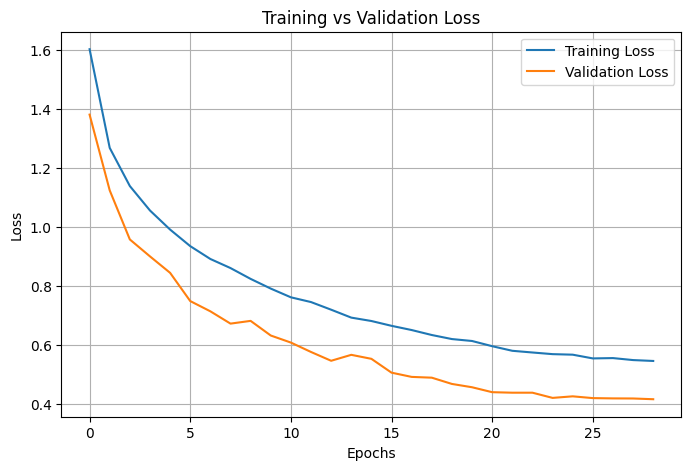

In [ ]:
#Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid()
plt.show()

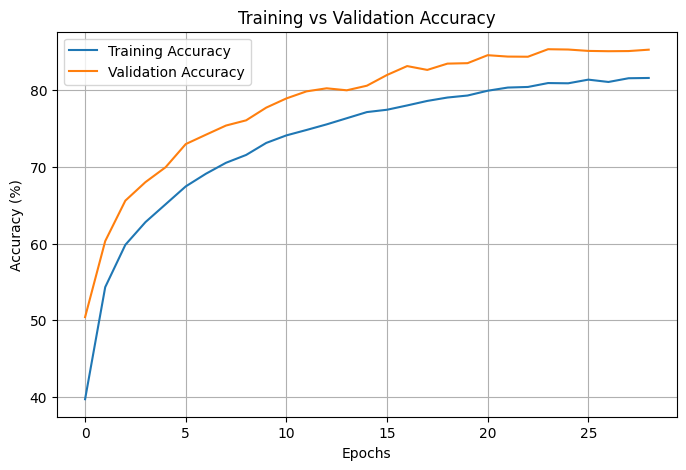

In [ ]:
#plot training nd validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid()
plt.show()

In [ ]:
#load the best model

model.load_state_dict(
    torch.load("best_cifar10_cnn.pth", map_location=device)
)

model.eval()

print("Best model loaded successfully.")

Best model loaded successfully.


In [ ]:
#evaluate the best model

test_correct = 0
test_total = 0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_accuracy = 100 * test_correct / test_total

print("Test Accuracy:", round(test_accuracy, 2), "%")

Test Accuracy: 84.6 %


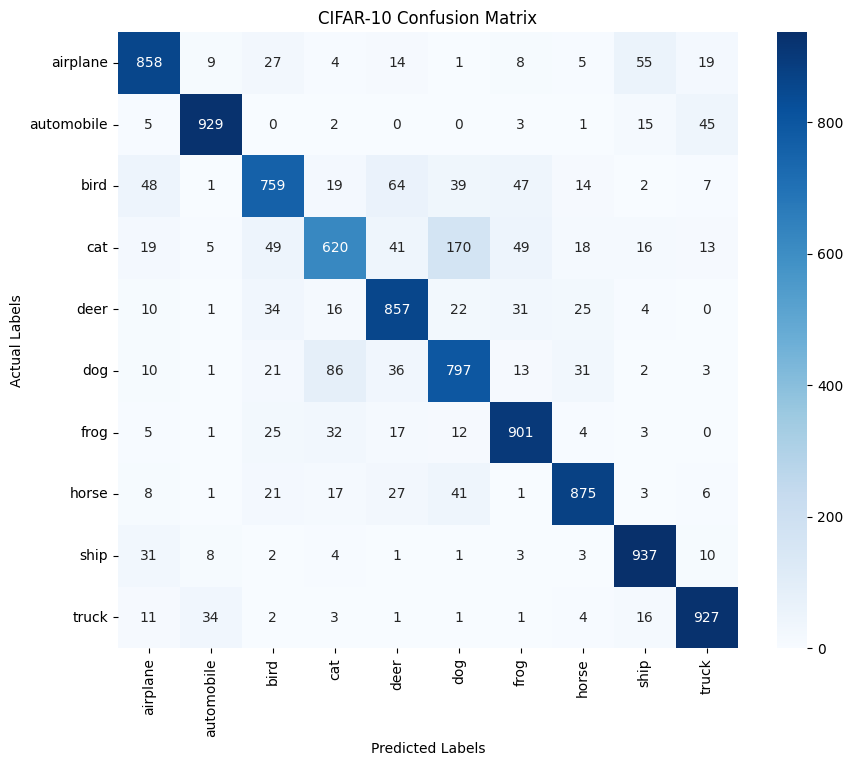

              precision    recall  f1-score   support

    airplane       0.85      0.86      0.86      1000
  automobile       0.94      0.93      0.93      1000
        bird       0.81      0.76      0.78      1000
         cat       0.77      0.62      0.69      1000
        deer       0.81      0.86      0.83      1000
         dog       0.74      0.80      0.76      1000
        frog       0.85      0.90      0.88      1000
       horse       0.89      0.88      0.88      1000
        ship       0.89      0.94      0.91      1000
       truck       0.90      0.93      0.91      1000

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.84     10000
weighted avg       0.85      0.85      0.84     10000



In [ ]:
#confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("CIFAR-10 Confusion Matrix")

plt.show()

#classification report

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=classes
    )
)


In [ ]:
#Final Model Performance

print("========== FINAL MODEL PERFORMANCE ==========")

print("Model: CNN from Scratch")
print("Dataset: CIFAR-10")

print("Number of Classes:", len(classes))

print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))

print("Best Validation Accuracy:", round(best_val_accuracy, 2), "%")
print("Final Test Accuracy:", round(test_accuracy, 2), "%")

print("Saved Model: best_cifar10_cnn.pth")

========== FINAL MODEL PERFORMANCE ==========
Model: CNN from Scratch
Dataset: CIFAR-10
Number of Classes: 10
Training Images: 45000
Validation Images: 5000
Testing Images: 10000
Best Validation Accuracy: 85.36 %
Final Test Accuracy: 84.6 %
Saved Model: best_cifar10_cnn.pth


#PHASE 3

In [ ]:
#save the trained model

torch.save(
    model.state_dict(),
    "cifar10_cnn_final.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import torch
from google.colab import files

# Save best trained model
torch.save(
    model.state_dict(),
    "best_cifar10_cnn.pth"
)

# Download model to your Mac
files.download("best_cifar10_cnn.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#PHASE 3

In [ ]:
!pip install -q gradio scikit-learn

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import gradio as gr

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from google.colab import files

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cpu


In [ ]:
uploaded = files.upload()

model_path = list(uploaded.keys())[0]

print("Uploaded model:", model_path)

Saving best_cifar10_cnn.pth to best_cifar10_cnn (1).pth
Uploaded model: best_cifar10_cnn (1).pth


In [ ]:
#LOAD DATASET AND CLASSES
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2
)

classes = test_dataset.classes

print("Classes:", classes)
print("Test images:", len(test_dataset))

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Test images: 10000


In [ ]:
#define CNN architecture

class CIFAR10_CNN(nn.Module):

    def __init__(self):
        super(CIFAR10_CNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.3),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.4),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
#load trained model
model = CIFAR10_CNN().to(device)

checkpoint = torch.load(
    model_path,
    map_location=device
)

# Support both direct state_dict and wrapped checkpoint
if "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

print("Trained model loaded successfully!")

Trained model loaded successfully!


In [ ]:
def gradio_predict(image):

    image = image.convert("RGB")

    transform_image = transforms.Compose([
        transforms.Resize((32, 32)),
        transforms.ToTensor(),
        transforms.Normalize(
            (0.4914, 0.4822, 0.4465),
            (0.2470, 0.2435, 0.2616)
        )
    ])

    image_tensor = transform_image(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():

        outputs = model(image_tensor)

        probabilities = torch.softmax(outputs, dim=1)

    probabilities = probabilities.cpu().numpy()[0]

    result = {
        classes[i]: float(probabilities[i])
        for i in range(len(classes))
    }

    return result


interface = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Image(type="pil", label="Upload Image"),
    outputs=gr.Label(
        num_top_classes=10,
        label="CIFAR-10 Predictions"
    ),
    title="CIFAR-10 Image Classification",
    description="Upload an image to classify it into one of 10 CIFAR-10 categories."
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://773353e7d2194725ec.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
